# Machine Learning Midterm — Wine Classification

This notebook covers Sections 1–10 for the **Wine Classification** dataset only.
Shared functions live in `helpers.py`; all data, models and results in this notebook belong to this dataset.
Run with **Kernel → Restart & Run All**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

import helpers as H

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.4f}".format)

DATASET = "wine"
DATASET_TITLE = "Wine Classification"
N_CLUSTERS = 3            # fixed by the assignment (class count)
POSITIVE_LABEL = None     # Wine uses macro one-vs-rest ROC-AUC; no single positive class
MANUAL_CHECK_CLASS = 1    # class used for the manual precision/recall/F1 check

print("Seeds:", H.SEEDS, "| test seed:", H.TEST_SEED, "| final evaluation seed:", H.EVAL_SEED)
print("Tree depths:", H.TREE_DEPTHS, "| KNN neighbours:", H.KNN_NEIGHBORS)
H.make_output_dirs()
H.package_versions()

Seeds: [42, 52, 62] | test seed: 42 | final evaluation seed: 42
Tree depths: [2, 3, 5, 10, None] | KNN neighbours: [1, 3, 5, 7, 11]


,package,version
0,python,3.13.17
1,platform,Windows-11-10.0.26200-SP0
2,numpy,2.5.3
3,pandas,3.0.5
4,scikit-learn,1.9.1
5,scipy,1.18.1
6,matplotlib,3.11.2


## 1. Loading the Datasets
### 1.1 Load the dataset from scikit-learn

In [2]:
# Loaded with sklearn.datasets.load_wine (inside H.load_dataset)
X, y, target_names = H.load_dataset(DATASET)
print(type(X), type(y))

<class 'pandas.DataFrame'> <class 'pandas.Series'>


### 1.2 Create the data frames

In [3]:
print("Shape of X:", X.shape, "| shape of y:", y.shape)
print("Target is NOT in X:", "target" not in X.columns)
X.head()

Shape of X: (178, 13) | shape of y: (178,)
Target is NOT in X: True


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.2300,1.7100,2.4300,15.6000,127.0000,2.8000,3.0600,0.2800,2.2900,5.6400,1.0400,3.9200,1065.0000
1,13.2000,1.7800,2.1400,11.2000,100.0000,2.6500,2.7600,0.2600,1.2800,4.3800,1.0500,3.4000,1050.0000
2,13.1600,2.3600,2.6700,18.6000,101.0000,2.8000,3.2400,0.3000,2.8100,5.6800,1.0300,3.1700,1185.0000
3,14.3700,1.9500,2.5000,16.8000,113.0000,3.8500,3.4900,0.2400,2.1800,7.8000,0.8600,3.4500,1480.0000
4,13.2400,2.5900,2.8700,21.0000,118.0000,2.8000,2.6900,0.3900,1.8200,4.3200,1.0400,2.9300,735.0000


In [4]:
print("Feature names:", list(X.columns))
print("Target labels:", sorted(y.unique()))
print("Target names:", target_names)
H.class_mapping_table(y, target_names)

Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target labels: [np.int64(0), np.int64(1), np.int64(2)]
Target names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,label,target_name,n_samples,percent
0,0,class_0,59,33.1500
1,1,class_1,71,39.8900
2,2,class_2,48,26.9700


> **Interpretation (write your own):** Number of samples/features, the class-label mapping (labels 0, 1, 2 kept as in scikit-learn) and whether the classes are balanced.

## 2. Dataset Quality Checks
### 2.1 Missing values and duplicates

In [5]:
missing = H.missing_values_table(X)
n_missing = int(missing["missing_count"].sum())
n_duplicates = int(X.duplicated().sum())
print("Total missing values:", n_missing)
print("Duplicate rows (features only):", n_duplicates)
print("Duplicate rows (features + target):", int(pd.concat([X, y], axis=1).duplicated().sum()))
if n_missing == 0:
    print("-> No missing values are present in any column.")
if n_duplicates == 0:
    print("-> No duplicate rows are present.")
NEEDS_IMPUTATION = n_missing > 0
missing.T

Total missing values: 0
Duplicate rows (features only): 0
Duplicate rows (features + target): 0
-> No missing values are present in any column.
-> No duplicate rows are present.


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
missing_count,0,0,0,0,0,0,0,0,0,0,0,0,0


### 2.2 Potential outliers (IQR 1.5 rule and |z| > 3) — nothing is deleted or clipped

In [6]:
outliers = H.outlier_table(X)
print("Features with at least one IQR outlier:", int((outliers["IQR_outliers"] > 0).sum()), "of", X.shape[1])
outliers.head(10)

Features with at least one IQR outlier: 7 of 13


,IQR_lower,IQR_upper,IQR_outliers,z>3_outliers,IQR_outlier_%
magnesium,59.5000,135.5000,4,2,2.2500
alcalinity_of_ash,10.7500,27.9500,4,1,2.2500
color_intensity,-1.2500,10.6700,4,1,2.2500
malic_acid,-0.6175,5.3025,3,1,1.6900
ash,1.6887,3.0788,3,3,1.6900
proanthocyanins,0.2000,3.0000,2,1,1.1200
hue,0.2762,1.6263,1,1,0.5600
alcohol,10.3900,15.6500,0,0,0.0000
total_phenols,0.1563,4.3862,0,0,0.0000
nonflavanoid_phenols,0.0188,0.6887,0,0,0.0000


### 2.3 Data types

In [7]:
dtypes, n_num, n_cat = H.dtype_summary(X)
print("Numerical features:", n_num, "| categorical features:", n_cat)
print(dtypes["dtype"].value_counts())
dtypes.T

Numerical features: 13 | categorical features: 0
dtype
float64    13
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


> **Interpretation (write your own):** State that there are no missing values/duplicates (or report them), that all features are numerical, and explain how large/small values affect the algorithms: KNN and K-Means use Euclidean distance, so extreme values and large-range features dominate distances; GaussianNB's mean/variance estimates are pulled by outliers; Decision Trees split on thresholds and are relatively robust. Outliers are kept.

## 3. Exploratory Data Analysis (EDA)
*Sections 2–3 are descriptive only; nothing here is used to select features, fit preprocessing or remove samples.*
### 3.1 Descriptive statistics

In [8]:
desc = H.descriptive_stats(X)
desc

,mean,median,min,max,std,Q1,Q3
alcohol,13.0006,13.0500,11.0300,14.8300,0.8118,12.3625,13.6775
malic_acid,2.3363,1.8650,0.7400,5.8000,1.1171,1.6025,3.0825
ash,2.3665,2.3600,1.3600,3.2300,0.2743,2.2100,2.5575
alcalinity_of_ash,19.4949,19.5000,10.6000,30.0000,3.3396,17.2000,21.5000
magnesium,99.7416,98.0000,70.0000,162.0000,14.2825,88.0000,107.0000
total_phenols,2.2951,2.3550,0.9800,3.8800,0.6259,1.7425,2.8000
flavanoids,2.0293,2.1350,0.3400,5.0800,0.9989,1.2050,2.8750
nonflavanoid_phenols,0.3619,0.3400,0.1300,0.6600,0.1245,0.2700,0.4375
proanthocyanins,1.5909,1.5550,0.4100,3.5800,0.5724,1.2500,1.9500
color_intensity,5.0581,4.6900,1.2800,13.0000,2.3183,3.2200,6.2000


### 3.2 Class distribution and correlations

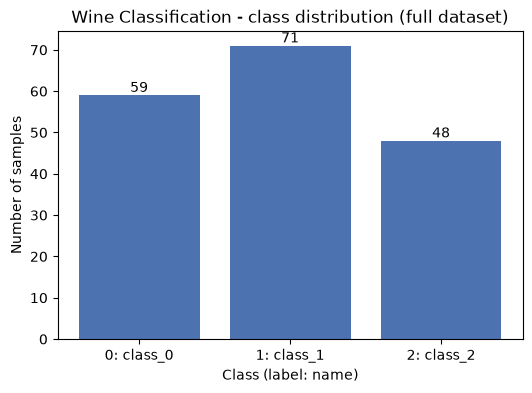

In [9]:
H.plot_class_distribution(y, target_names, DATASET_TITLE, f"{DATASET}_class_distribution")

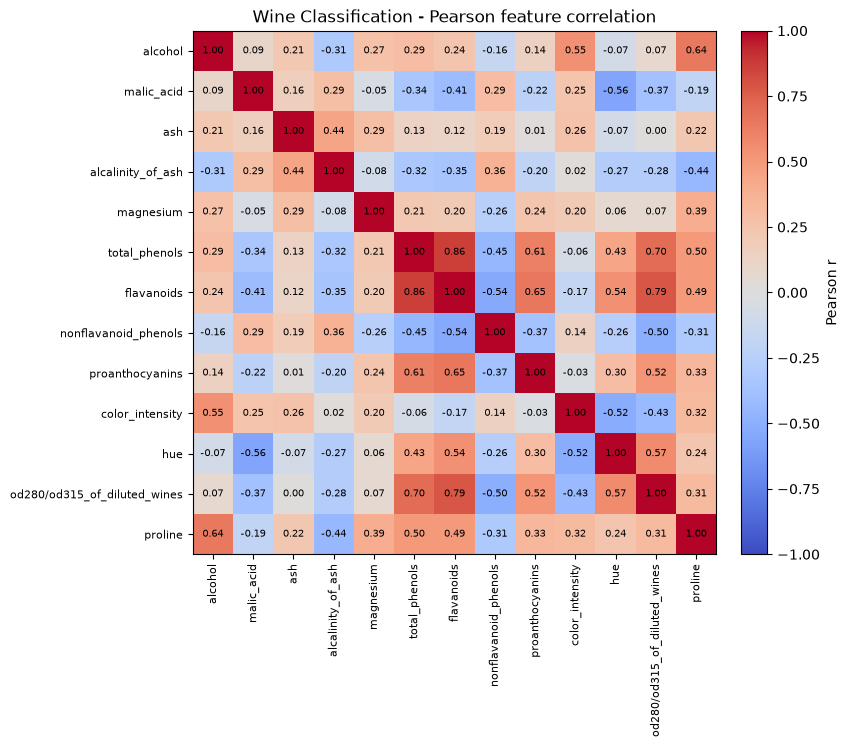

,feature_1,feature_2,r,abs_r
0,total_phenols,flavanoids,0.8646,0.8646
1,flavanoids,od280/od315_of_diluted_wines,0.7872,0.7872
2,total_phenols,od280/od315_of_diluted_wines,0.6999,0.6999


In [10]:
corr = H.plot_correlation_heatmap(X, DATASET_TITLE, f"{DATASET}_correlation_heatmap")
top_pairs = H.top_correlated_pairs(corr, k=3)
top_pairs

### 3.3 Boxplots (each feature on its own scale)

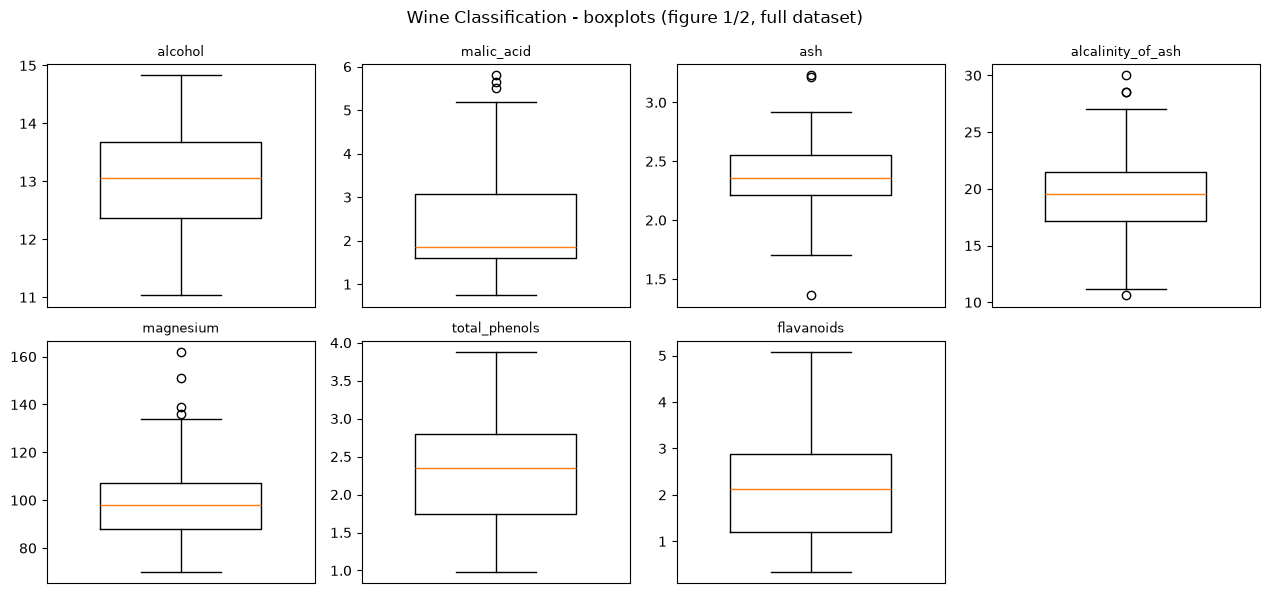

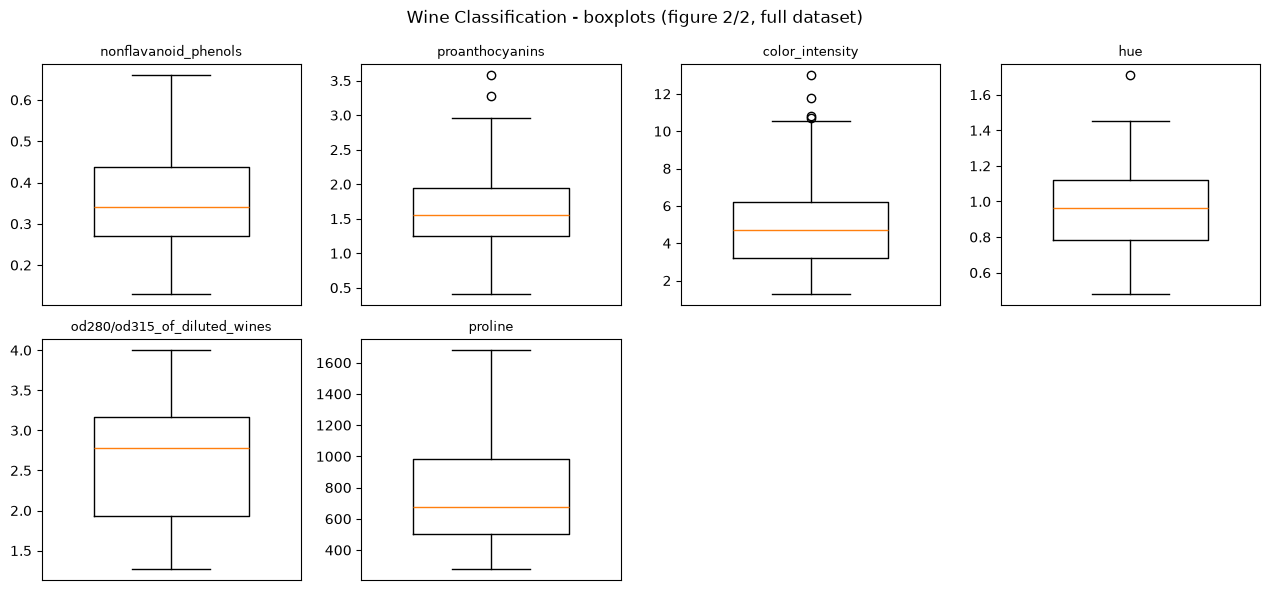

In [11]:
H.plot_boxplots(X, DATASET_TITLE, f"{DATASET}_boxplots", per_fig=7, ncols=4)

> **Interpretation (write your own):** Discuss the class balance, the three strongest unique correlated pairs above (and why they are related), and at least two boxplot observations about feature ranges/outliers (e.g. features whose ranges differ by orders of magnitude — the reason scaling matters for KNN and K-Means).

## 4. Splitting the Datasets
### 4.1 Fixed test set + three training/validation repetitions

In [12]:
X_test, y_test, splits = H.make_splits(X, y)
# Per-seed subsets are stored separately, e.g. splits[52]["X_train"]; original row indices are preserved.
for seed in H.SEEDS:
    s = splits[seed]
    print(f"seed {seed}: X_train {s['X_train'].shape}, X_val {s['X_val'].shape}, X_test {X_test.shape}")
print("First test indices:", list(X_test.index[:10]))

seed 42: X_train (124, 13), X_val (18, 13), X_test (36, 13)
seed 52: X_train (124, 13), X_val (18, 13), X_test (36, 13)
seed 62: X_train (124, 13), X_val (18, 13), X_test (36, 13)
First test indices: [10, 134, 28, 121, 62, 51, 7, 66, 129, 166]


### 4.2 Verify the split

In [13]:
split_table = H.split_summary(y, y_test, splits, target_names)
split_table.insert(0, "dataset", DATASET)
split_table

,dataset,seed,subset,n,percent,class_0_class_0,class_1_class_1,class_2_class_2
0,wine,42,train,124,69.6600,41,50,33
1,wine,42,validation,18,10.1100,6,7,5
2,wine,42,test,36,20.2200,12,14,10
3,wine,52,train,124,69.6600,41,50,33
4,wine,52,validation,18,10.1100,6,7,5
5,wine,52,test,36,20.2200,12,14,10
6,wine,62,train,124,69.6600,41,50,33
7,wine,62,validation,18,10.1100,6,7,5
8,wine,62,test,36,20.2200,12,14,10


In [14]:
H.verify_splits(X, y_test, splits)

,seed,train∩val,train∩test,val∩test,sum_of_counts,dataset_size,covers_all_rows,test_indices_same_as_seed42
0,42,0,0,0,178,178,True,True
1,52,0,0,0,178,178,True,True
2,62,0,0,0,178,178,True,True


In [15]:
# Inspectable original row indices (saved to CSV for inspection)
split_indices = H.split_indices_table(y_test, splits)
split_indices.to_csv(H.RES_DIR / f"{DATASET}_split_indices.csv", index=False)
split_indices.groupby(["seed", "subset"]).row_index.apply(lambda s: list(s[:8])).to_frame("first 8 indices")

first 8 indices
seed subset                                             
42   test              [10, 134, 28, 121, 62, 51, 7, 66]
     train       [163, 148, 116, 122, 115, 147, 46, 141]
     validation      [157, 145, 158, 110, 6, 120, 0, 89]
52   test              [10, 134, 28, 121, 62, 51, 7, 66]
     train         [128, 135, 53, 27, 172, 141, 169, 11]
     validation     [165, 116, 69, 45, 34, 146, 114, 91]
62   test              [10, 134, 28, 121, 62, 51, 7, 66]
     train          [13, 97, 140, 156, 11, 136, 77, 161]
     validation       [168, 175, 29, 68, 67, 124, 2, 15]

> **Interpretation (write your own):** The test set is reserved once (random_state=42) and is identical in all repetitions; the seeds only change train/validation membership. Mention that repetitions overlap and are not independent datasets or CV folds.

## 5. Data Preprocessing and Scaling
### 5.1 Missing values

In [16]:
if NEEDS_IMPUTATION:
    print("Missing values found -> a median SimpleImputer is fitted on each training subset only.")
else:
    print("No missing values exist -> no imputation step is added.")

No missing values exist -> no imputation step is added.


### 5.2 Selected scaler: `StandardScaler` (same type for both datasets and all seeds)
### 5.3 Fit on training data only (one new scaler per seed)

In [17]:
reps, prep, test_reps = H.build_representations(X_test, splits, NEEDS_IMPUTATION)
for seed in H.SEEDS:
    sc = prep[seed]["scaler"]
    print(f"seed {seed}: scaler fitted on {sc.n_samples_seen_} training rows | id={id(sc)}")
print("Test set transformed with the seed-42 scaler only:", test_reps["scaled"].shape)

seed 42: scaler fitted on 124.0 training rows | id=2289412080368
seed 52: scaler fitted on 124.0 training rows | id=2289456189264
seed 62: scaler fitted on 124.0 training rows | id=2289456189904
Test set transformed with the seed-42 scaler only: (36, 13)


In [18]:
print("Seed 42 — first five TRAINING rows BEFORE scaling")
display(reps[42]["unscaled"]["X_train"].head())
print("Seed 42 — the same rows AFTER StandardScaler")
display(reps[42]["scaled"]["X_train"].head())
print("Scaled training data: mean ≈ 0, std ≈ 1 per feature")
reps[42]["scaled"]["X_train"].agg(["mean", "std"]).round(3)

Seed 42 — first five TRAINING rows BEFORE scaling


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.9600,3.4500,2.3500,18.5000,106.0000,1.3900,0.7000,0.4000,0.9400,5.2800,0.6800,1.7500,675.0000
148,13.3200,3.2400,2.3800,21.5000,92.0000,1.9300,0.7600,0.4500,1.2500,8.4200,0.5500,1.6200,650.0000
116,11.8200,1.4700,1.9900,20.8000,86.0000,1.9800,1.6000,0.3000,1.5300,1.9500,0.9500,3.3300,495.0000
122,12.4200,4.4300,2.7300,26.5000,102.0000,2.2000,2.1300,0.4300,1.7100,2.0800,0.9200,3.1200,365.0000
115,11.0300,1.5100,2.2000,21.5000,85.0000,2.4600,2.1700,0.5200,2.0100,1.9000,1.7100,2.8700,407.0000


Seed 42 — the same rows AFTER StandardScaler


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.0175,1.0892,-0.0401,-0.3084,0.4332,-1.3425,-1.3223,0.3527,-1.1176,0.1258,-1.2268,-1.2236,-0.2094
148,0.4397,0.8918,0.0729,0.6094,-0.5057,-0.4910,-1.2599,0.7699,-0.5719,1.5123,-1.8114,-1.4147,-0.2914
116,-1.4654,-0.7720,-1.3968,0.3953,-0.9081,-0.4121,-0.3865,-0.4819,-0.0789,-1.3445,-0.0125,1.0978,-0.8000
122,-0.7033,2.0104,1.3920,2.1391,0.1650,-0.0652,0.1645,0.6030,0.2380,-1.2871,-0.1475,0.7893,-1.2265
115,-2.4687,-0.7344,-0.6054,0.6094,-0.9752,0.3448,0.2061,1.3541,0.7661,-1.3665,3.4052,0.4219,-1.0887


Scaled training data: mean ≈ 0, std ≈ 1 per feature


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
mean,-0.0000,-0.0000,-0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0000,-0.0000,0.0000,-0.0000
std,1.0040,1.0040,1.0040,1.0040,1.0040,1.0040,1.0040,1.0040,1.0040,1.0040,1.0040,1.0040,1.0040


> **Interpretation (write your own):** Explain why StandardScaler was chosen and how values changed: z = (x − training mean) / training std, so each feature now has mean ≈ 0 and std ≈ 1 on the training subset; validation/test values are transformed with the training statistics, so they are not exactly 0/1.

## 6. Preparing the Two Data Representations

In [19]:
for seed in H.SEEDS:
    for rep in H.REPRESENTATIONS:
        Xtr, Xva = reps[seed][rep]["X_train"], reps[seed][rep]["X_val"]
        assert Xtr.index.equals(splits[seed]["X_train"].index)
        assert Xva.index.equals(splits[seed]["X_val"].index)
        assert list(Xtr.columns) == list(X.columns)
print("Both representations use the same rows and all original features for every seed.")

Both representations use the same rows and all original features for every seed.


## 7. Training the Classification Models
### 7.1 Required experiments (5 + 5 + 1 settings × 2 representations × 3 seeds = 66 fits)

In [20]:
runs, models_s42 = H.run_classifiers(DATASET, reps, splits, POSITIVE_LABEL)
print("Classifier runs:", len(runs), "| seed-42 fitted models kept:", len(models_s42))
print(runs.groupby(["algorithm", "representation"]).size())

Classifier runs: 66 | seed-42 fitted models kept: 22
algorithm      representation
decision_tree  scaled            15
               unscaled          15
gaussian_nb    scaled             3
               unscaled           3
knn            scaled            15
               unscaled          15
dtype: int64


### 7.2 Run log (all 66 runs, including low-scoring ones)

In [21]:
runs

,dataset,run_id,config_id,seed,algorithm,representation,parameter,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc,val_precision_undefined_classes,val_recall_undefined_classes
0,wine,wine_decision_tree_unscaled_depth2_s42,wine_decision_tree_unscaled_depth2,42,decision_tree,unscaled,depth2,0.9355,0.9297,0.8333,0.8631,0.8111,0.8175,0.9106,,
1,wine,wine_decision_tree_unscaled_depth3_s42,wine_decision_tree_unscaled_depth3,42,decision_tree,unscaled,depth3,0.9919,0.9926,0.9444,0.9583,0.9444,0.9475,0.9686,,
2,wine,wine_decision_tree_unscaled_depth5_s42,wine_decision_tree_unscaled_depth5,42,decision_tree,unscaled,depth5,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571,,
3,wine,wine_decision_tree_unscaled_depth10_s42,wine_decision_tree_unscaled_depth10,42,decision_tree,unscaled,depth10,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571,,
4,wine,wine_decision_tree_unscaled_depthNone_s42,wine_decision_tree_unscaled_depthNone,42,decision_tree,unscaled,depthNone,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,wine,wine_knn_scaled_k3_s62,wine_knn_scaled_k3,62,knn,scaled,k3,0.9597,0.9609,0.8889,0.8968,0.9048,0.8885,1.0000,,
62,wine,wine_knn_scaled_k5_s62,wine_knn_scaled_k5,62,knn,scaled,k5,0.9758,0.9759,0.9444,0.9444,0.9524,0.9441,1.0000,,
63,wine,wine_knn_scaled_k7_s62,wine_knn_scaled_k7,62,knn,scaled,k7,0.9677,0.9684,0.9444,0.9444,0.9524,0.9441,1.0000,,
64,wine,wine_knn_scaled_k11_s62,wine_knn_scaled_k11,62,knn,scaled,k11,0.9677,0.9684,0.9444,0.9444,0.9524,0.9441,1.0000,,


## 8. Measuring Validation Performance
### 8.1 Undefined precision/recall check (before `zero_division=0`)

In [22]:
undef = runs[(runs.val_precision_undefined_classes != "") | (runs.val_recall_undefined_classes != "")]
if undef.empty:
    print("No run had a class with undefined precision or recall on its validation subset.")
else:
    display(undef[["run_id", "val_precision_undefined_classes", "val_recall_undefined_classes"]])

No run had a class with undefined precision or recall on its validation subset.


### 8.2 Summary over seeds (22 rows) and model selection

In [23]:
summary = H.summarise_runs(runs)
summary

,dataset,config_id,algorithm,representation,parameter,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std,n_seeds
0,wine,wine_decision_tree_unscaled_depth2,decision_tree,unscaled,depth2,0.9355,0.0081,0.9365,0.0106,0.8519,0.0321,0.8724,0.0214,0.8487,0.0495,0.8481,0.0365,0.9050,0.0219,3
1,wine,wine_decision_tree_unscaled_depth3,decision_tree,unscaled,depth3,0.9919,0.0000,0.9926,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9611,0.0431,3
2,wine,wine_decision_tree_unscaled_depth5,decision_tree,unscaled,depth5,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457,3
3,wine,wine_decision_tree_unscaled_depth10,decision_tree,unscaled,depth10,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457,3
4,wine,wine_decision_tree_unscaled_depthNone,decision_tree,unscaled,depthNone,1.0000,0.0000,1.0000,0.0000,0.9444,0.0556,0.9614,0.0371,0.9407,0.0612,0.9462,0.0545,0.9552,0.0457,3
5,wine,wine_knn_unscaled_k1,knn,unscaled,k1,1.0000,0.0000,1.0000,0.0000,0.7037,0.0321,0.6886,0.0239,0.6836,0.0223,0.6714,0.0226,0.7654,0.0181,3
6,wine,wine_knn_unscaled_k3,knn,unscaled,k3,0.8360,0.0123,0.8294,0.0134,0.6667,0.0556,0.6614,0.0496,0.6519,0.0478,0.6456,0.0429,0.8333,0.0311,3
7,wine,wine_knn_unscaled_k5,knn,unscaled,k5,0.7876,0.0093,0.7739,0.0091,0.7037,0.0321,0.7280,0.0722,0.6862,0.0294,0.6667,0.0399,0.8645,0.0115,3
8,wine,wine_knn_unscaled_k7,knn,unscaled,k7,0.7903,0.0213,0.7804,0.0231,0.6667,0.0000,0.6471,0.0225,0.6545,0.0153,0.6356,0.0316,0.8459,0.0084,3
9,wine,wine_knn_unscaled_k11,knn,unscaled,k11,0.7392,0.0093,0.7309,0.0083,0.6296,0.0321,0.6148,0.0127,0.6138,0.0211,0.6005,0.0010,0.8216,0.0254,3


In [24]:
selected, ranked = H.select_configuration(summary)
SELECTED_CONFIG = selected["config_id"]
print("Selected configuration:", SELECTED_CONFIG)
print(f"mean val macro-F1 = {selected['val_macro_f1_mean']:.4f} ± {selected['val_macro_f1_std']:.4f}")
ranked[["config_id", "val_macro_f1_mean", "val_macro_f1_std", "val_accuracy_mean",
        "train_macro_f1_mean"]].head(8)

Selected configuration: wine_knn_scaled_k11
mean val macro-F1 = 0.9814 ± 0.0323


,config_id,val_macro_f1_mean,val_macro_f1_std,val_accuracy_mean,train_macro_f1_mean
0,wine_knn_scaled_k11,0.9814,0.0323,0.9815,0.9656
1,wine_knn_scaled_k5,0.9814,0.0323,0.9815,0.9762
2,wine_knn_scaled_k7,0.9814,0.0323,0.9815,0.9603
3,wine_knn_scaled_k1,0.9658,0.0296,0.9630,1.0000
4,wine_gaussian_nb_scaled_default,0.9638,0.0314,0.9630,0.9840
5,wine_gaussian_nb_unscaled_default,0.9638,0.0314,0.9630,0.9840
6,wine_decision_tree_scaled_depth10,0.9462,0.0545,0.9444,1.0000
7,wine_decision_tree_scaled_depth3,0.9462,0.0545,0.9444,0.9926


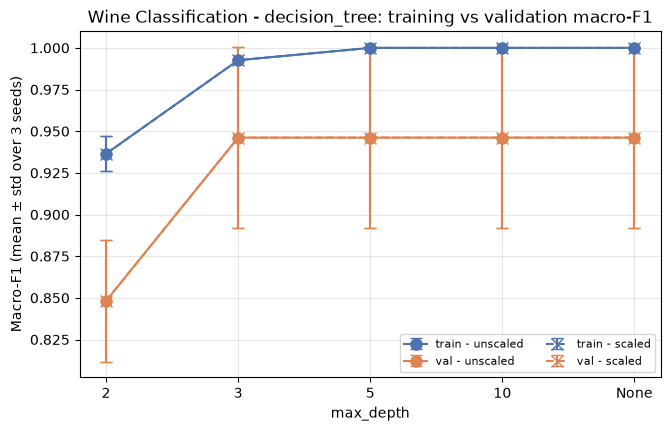

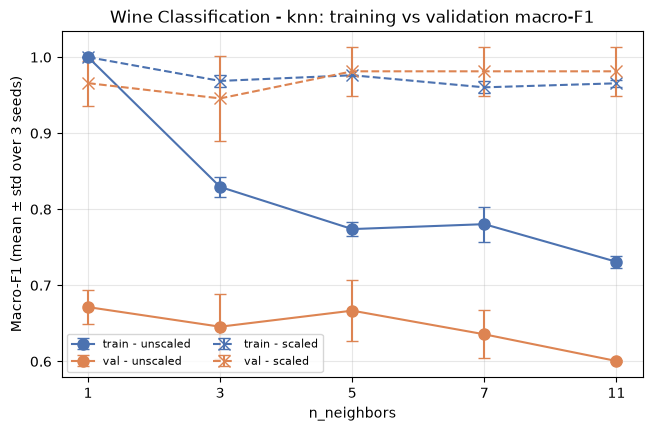

In [25]:
H.plot_param_curve(summary, "decision_tree", H.TREE_DEPTHS, "depth", "max_depth",
                   DATASET_TITLE, f"{DATASET}_tree_depth_macro_f1")
H.plot_param_curve(summary, "knn", H.KNN_NEIGHBORS, "k", "n_neighbors",
                   DATASET_TITLE, f"{DATASET}_knn_neighbors_macro_f1")

In [26]:
# Scaling effect: mean validation macro-F1 (scaled − unscaled) per setting
H.scaling_effect_table(summary)

representation           scaled  unscaled  scaled_minus_unscaled
algorithm     parameter                                         
knn           k11        0.9814    0.6005                 0.3809
              k7         0.9814    0.6356                 0.3458
              k5         0.9814    0.6667                 0.3146
              k3         0.9457    0.6456                 0.3002
              k1         0.9658    0.6714                 0.2944
decision_tree depth10    0.9462    0.9462                 0.0000
              depth2     0.8481    0.8481                 0.0000
              depth3     0.9462    0.9462                 0.0000
gaussian_nb   default    0.9638    0.9638                 0.0000
decision_tree depth5     0.9462    0.9462                 0.0000
              depthNone  0.9462    0.9462                 0.0000

In [27]:
# Training/validation gap per configuration
gap = summary[["config_id", "train_macro_f1_mean", "val_macro_f1_mean", "val_macro_f1_std"]].copy()
gap["train_minus_val"] = gap.train_macro_f1_mean - gap.val_macro_f1_mean
gap.sort_values("train_minus_val", ascending=False)

,config_id,train_macro_f1_mean,val_macro_f1_mean,val_macro_f1_std,train_minus_val
5,wine_knn_unscaled_k1,1.0000,0.6714,0.0226,0.3286
6,wine_knn_unscaled_k3,0.8294,0.6456,0.0429,0.1838
8,wine_knn_unscaled_k7,0.7804,0.6356,0.0316,0.1448
9,wine_knn_unscaled_k11,0.7309,0.6005,0.0010,0.1304
7,wine_knn_unscaled_k5,0.7739,0.6667,0.0399,0.1072
0,wine_decision_tree_unscaled_depth2,0.9365,0.8481,0.0365,0.0883
11,wine_decision_tree_scaled_depth2,0.9365,0.8481,0.0365,0.0883
4,wine_decision_tree_unscaled_depthNone,1.0000,0.9462,0.0545,0.0538
2,wine_decision_tree_unscaled_depth5,1.0000,0.9462,0.0545,0.0538
3,wine_decision_tree_unscaled_depth10,1.0000,0.9462,0.0545,0.0538


> **Interpretation (write your own):** Discuss scaling effects (use numbers from the scaling table), how depth and k change performance, the train/validation gaps (overfitting, e.g. depth=None or k=1 reach training F1 = 1.0), and seed variability. The std describes these three repeated splits only; it is not a confidence interval.

## 9. Evaluating the Selected Model on the Test Set
Only the **seed-42** fitted instance of the selected configuration is evaluated, using seed-42 preprocessing.

In [28]:
final_model = models_s42[SELECTED_CONFIG]
final_rep = selected["representation"]
X_test_eval = test_reps[final_rep]
y_test_pred = final_model.predict(X_test_eval)
labels = list(final_model.classes_)
print("Final model:", final_model, "| representation:", final_rep)

Final model: KNeighborsClassifier(metric='euclidean', n_neighbors=11) | representation: scaled


### 9.1 Final performance metrics

In [29]:
test_metrics = H.classification_metrics(final_model, X_test_eval, y_test, DATASET, POSITIVE_LABEL)
classifier_test = pd.DataFrame([{
    "dataset": DATASET, "selected_config": SELECTED_CONFIG, "eval_seed": H.EVAL_SEED,
    "mean_val_macro_f1": selected["val_macro_f1_mean"], "std_val_macro_f1": selected["val_macro_f1_std"],
    **{f"test_{k}": v for k, v in test_metrics.items()
       if k not in ("precision_undefined_classes", "recall_undefined_classes")},
}])
print("Undefined precision classes:", test_metrics["precision_undefined_classes"] or "none",
      "| undefined recall classes:", test_metrics["recall_undefined_classes"] or "none")
classifier_test

Undefined precision classes: none | undefined recall classes: none


,dataset,selected_config,eval_seed,mean_val_macro_f1,std_val_macro_f1,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,wine,wine_knn_scaled_k11,42,0.9814,0.0323,1.0000,1.0000,1.0000,1.0000,1.0000


In [30]:
print(classification_report(y_test, y_test_pred, labels=labels,
                            target_names=[f"{l}: {target_names[l]}" for l in labels],
                            digits=4, zero_division=0))
report_df = pd.DataFrame(classification_report(y_test, y_test_pred, labels=labels, output_dict=True,
                                               zero_division=0)).T

              precision    recall  f1-score   support

  0: class_0     1.0000    1.0000    1.0000        12
  1: class_1     1.0000    1.0000    1.0000        14
  2: class_2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



### 9.2 Confusion matrix

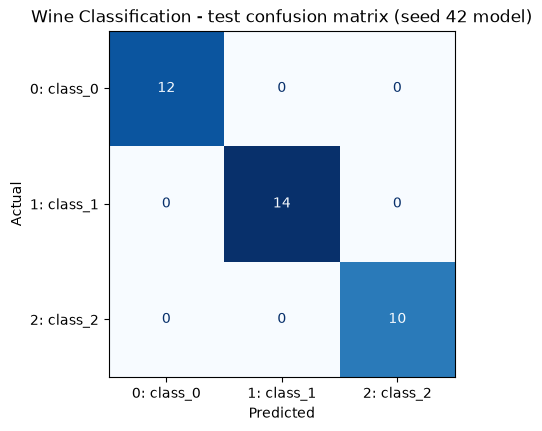

,Predicted 0: class_0,Predicted 1: class_1,Predicted 2: class_2
Actual 0: class_0,12,0,0
Actual 1: class_1,0,14,0
Actual 2: class_2,0,0,10


In [31]:
cm_df = H.plot_confusion(y_test, y_test_pred, labels, target_names, DATASET_TITLE,
                         f"{DATASET}_test_confusion_matrix")
cm = cm_df.values
cm_df

In [32]:
off = cm.copy()
np.fill_diagonal(off, 0)
if off.sum() == 0:
    print("The selected classifier made no test errors - there is no off-diagonal confusion.")
else:
    i, j = np.unravel_index(off.argmax(), off.shape)
    print(f"Largest off-diagonal confusion: {off[i, j]} sample(s) of actual class {labels[i]} "
          f"({target_names[labels[i]]}) predicted as class {labels[j]} ({target_names[labels[j]]}).")

The selected classifier made no test errors - there is no off-diagonal confusion.


**Manual metric check** (compared with the per-class row of the classification report, not the macro average)

In [33]:
manual = H.manual_one_vs_rest(cm, labels, MANUAL_CHECK_CLASS)
rep_row = report_df.loc[str(MANUAL_CHECK_CLASS)]
tp, fp, fn = manual["TP"], manual["FP"], manual["FN"]
print(f"Class {MANUAL_CHECK_CLASS} ({target_names[MANUAL_CHECK_CLASS]}) vs rest: TP={tp}, FP={fp}, FN={fn}, TN={manual['TN']}")
print(f"precision = TP/(TP+FP) = {tp}/({tp}+{fp}) = {manual['precision']:.4f}" if tp + fp else "precision undefined (TP+FP=0)")
print(f"recall    = TP/(TP+FN) = {tp}/({tp}+{fn}) = {manual['recall']:.4f}" if tp + fn else "recall undefined (TP+FN=0)")
print(f"F1        = 2PR/(P+R)            = {manual['f1']:.4f}")
pd.DataFrame({"manual": [manual["precision"], manual["recall"], manual["f1"]],
              "classification_report": [rep_row["precision"], rep_row["recall"], rep_row["f1-score"]]},
             index=["precision", "recall", "f1"])

Class 1 (class_1) vs rest: TP=14, FP=0, FN=0, TN=22
precision = TP/(TP+FP) = 14/(14+0) = 1.0000
recall    = TP/(TP+FN) = 14/(14+0) = 1.0000
F1        = 2PR/(P+R)            = 1.0000


,manual,classification_report
precision,1.0000,1.0000
recall,1.0000,1.0000
f1,1.0000,1.0000


### 9.3 ROC curves (one-vs-rest)

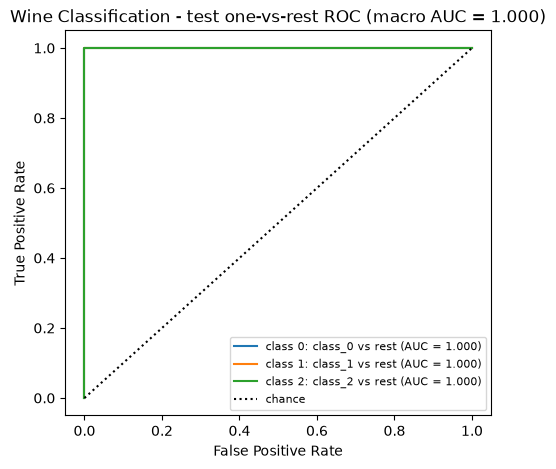

Class-specific AUCs: {np.int64(0): 1.0, np.int64(1): 1.0, np.int64(2): 1.0}
Macro one-vs-rest AUC: 1.0000


In [34]:
class_aucs, macro_auc = H.plot_roc_ovr(final_model, X_test_eval, y_test, target_names,
                                        DATASET_TITLE, f"{DATASET}_test_roc")
print("Class-specific AUCs:", {k: round(v, 4) for k, v in class_aucs.items()})
print(f"Macro one-vs-rest AUC: {macro_auc:.4f}")

### 9.4 Error interpretation

In [35]:
errors = H.misclassified_table(final_model, X_test_eval, y_test, target_names)
print("Misclassified test samples:", len(errors), "of", len(y_test))
errors

Misclassified test samples: 0 of 36


,true,predicted,P(class 0: class_0),P(class 1: class_1),P(class 2: class_2)


> **Interpretation (write your own):** Compare validation vs test results (without changing the model), explain TP/FP/FN/TN and the largest off-diagonal confusion, describe how lowering/raising the decision threshold trades false positives against false negatives, describe one misclassified sample from the table above (or why zero errors does not prove perfect generalisation), and state a limitation (small validation subsets, overlapping repetitions, single seed-42 test).

## 10. K-Means Clustering
### 10.1 Fit on training features (no labels), 2 representations × 3 seeds = 6 fits

In [36]:
km_runs, km_models_s42 = H.run_kmeans(DATASET, reps, splits, N_CLUSTERS)
km_runs

,dataset,run_id,seed,representation,n_clusters,train_inertia,val_ari,val_silhouette,val_n_distinct_clusters
0,wine,wine_kmeans_unscaled_c3_s42,42,unscaled,3,1350496.4591,0.2828,0.4870,3
1,wine,wine_kmeans_scaled_c3_s42,42,scaled,3,874.7391,1.0000,0.2516,3
2,wine,wine_kmeans_unscaled_c3_s52,52,unscaled,3,1303674.8207,0.4006,0.5559,3
3,wine,wine_kmeans_scaled_c3_s52,52,scaled,3,890.4355,1.0000,0.3010,3
4,wine,wine_kmeans_unscaled_c3_s62,62,unscaled,3,1390754.2171,0.4006,0.6867,3
5,wine,wine_kmeans_scaled_c3_s62,62,scaled,3,872.2466,1.0000,0.2726,3


In [37]:
km_summary = H.summarise_kmeans(km_runs)
km_summary

,dataset,representation,train_inertia_mean,train_inertia_std,train_inertia_valid_seeds,val_ari_mean,val_ari_std,val_ari_valid_seeds,val_silhouette_mean,val_silhouette_std,val_silhouette_valid_seeds
0,wine,unscaled,1348308.4990,43580.9098,3,0.3613,0.0680,3,0.5765,0.1014,3
1,wine,scaled,879.1404,9.8609,3,1.0000,0.0000,3,0.2751,0.0248,3


*Raw inertia is not comparable between the scaled and unscaled feature spaces (different units).*
### 10.2 Final cluster evaluation on the fixed test set (seed 42, no new fits)

In [38]:
km_test, contingency, test_clusters = H.kmeans_test_eval(DATASET, km_models_s42, test_reps, y_test, N_CLUSTERS)
km_test

,dataset,representation,eval_seed,n_clusters,n_test,test_ari,test_silhouette,cluster_0_count,cluster_1_count,cluster_2_count
0,wine,unscaled,42,3,36,0.3733,0.4929,14,10,12
1,wine,scaled,42,3,36,0.9088,0.2711,13,13,10


In [39]:
for rep in H.REPRESENTATIONS:
    print(f"Class-vs-cluster contingency table — {DATASET_TITLE}, {rep}, test set, seed-42 K-Means")
    display(contingency[rep])

Class-vs-cluster contingency table — Wine Classification, unscaled, test set, seed-42 K-Means


cluster ID,0,1,2
true class,,,
0,2,10,0
1,5,0,9
2,7,0,3


Class-vs-cluster contingency table — Wine Classification, scaled, test set, seed-42 K-Means


cluster ID,0,1,2
true class,,,
0,12,0,0
1,1,13,0
2,0,0,10


### 10.3 Visualise the clusters

Chosen features (highest ANOVA F on seed-42 training data, visualisation only): ['flavanoids', 'proline']


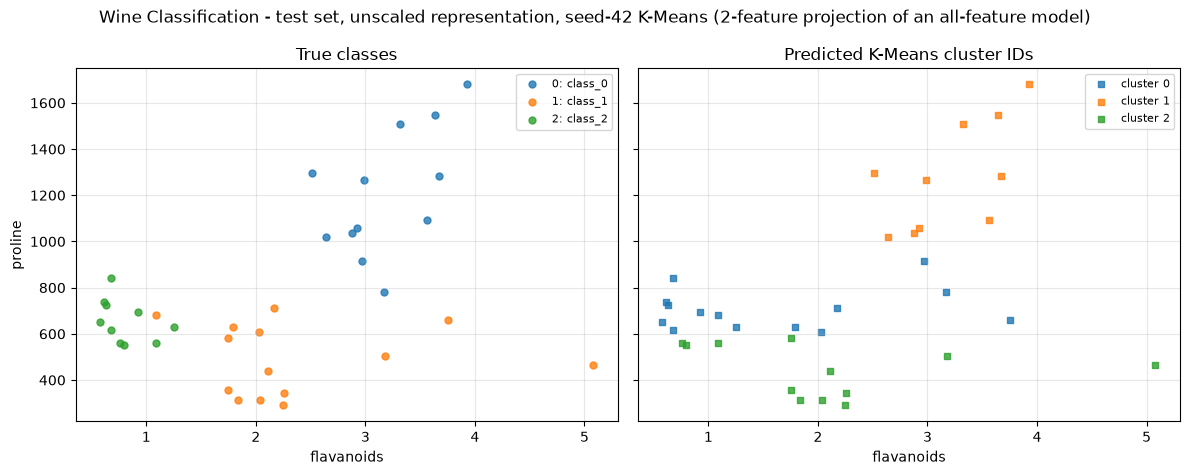

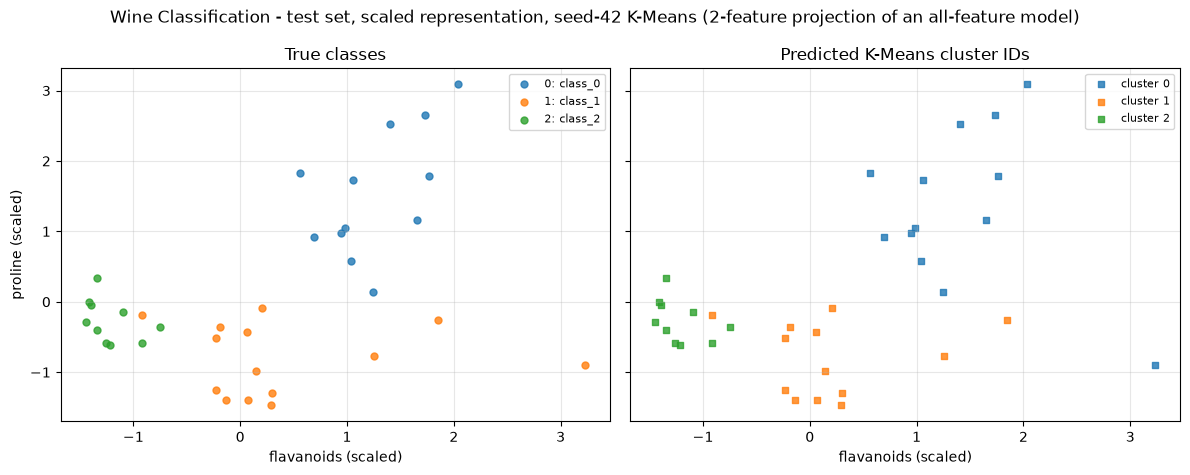

In [40]:
plot_features, f_scores = H.choose_plot_features(splits[42]["X_train"], splits[42]["y_train"])
print("Chosen features (highest ANOVA F on seed-42 training data, visualisation only):", plot_features)
for rep in H.REPRESENTATIONS:
    H.plot_class_vs_cluster(test_reps[rep], y_test, test_clusters[rep], plot_features, target_names, rep,
                            DATASET_TITLE, f"{DATASET}_kmeans_{rep}_class_vs_cluster")

> **Interpretation (write your own):** Use ARI and the contingency tables to say which classes are mixed within clusters and how scaling changed the partition (do not call ARI an accuracy). The plots are 2-feature projections of an all-feature model. Explain that K-Means never saw the labels during fitting, whereas the classifiers were trained with y_train.

## Export of result files (Section 12)
This notebook writes its own part; the six combined CSVs include every dataset whose notebook has been run.

In [41]:
export_status = H.export_results(DATASET, {
    "classifier_runs": runs, "classifier_summary": summary, "classifier_test": classifier_test,
    "kmeans_runs": km_runs, "kmeans_summary": km_summary, "kmeans_test": km_test,
})
export_status

,file,rows,expected_rows_both_datasets,datasets_included,complete
0,classifier_runs.csv,132,132,"breast_cancer, wine",True
1,classifier_summary.csv,44,44,"breast_cancer, wine",True
2,classifier_test.csv,2,2,"breast_cancer, wine",True
3,kmeans_runs.csv,12,12,"breast_cancer, wine",True
4,kmeans_summary.csv,4,4,"breast_cancer, wine",True
5,kmeans_test.csv,4,4,"breast_cancer, wine",True


In [42]:
print("Figures saved:", len(list(H.FIG_DIR.glob(f"{DATASET}_*.png"))))
sorted(p.name for p in H.FIG_DIR.glob(f"{DATASET}_*.png"))

Figures saved: 10


['wine_boxplots_1.png',
 'wine_boxplots_2.png',
 'wine_class_distribution.png',
 'wine_correlation_heatmap.png',
 'wine_kmeans_scaled_class_vs_cluster.png',
 'wine_kmeans_unscaled_class_vs_cluster.png',
 'wine_knn_neighbors_macro_f1.png',
 'wine_test_confusion_matrix.png',
 'wine_test_roc.png',
 'wine_tree_depth_macro_f1.png']